In [108]:
import pandas as pd
import numpy as np
import seaborn as sns

In [109]:
data= pd.read_csv("zomato.csv", engine="python", on_bad_lines="skip")

In [110]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 51155 entries, 0 to 51154
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51155 non-null  str  
 1   address                      51155 non-null  str  
 2   name                         51155 non-null  str  
 3   online_order                 51155 non-null  str  
 4   book_table                   51155 non-null  str  
 5   rate                         43380 non-null  str  
 6   votes                        51155 non-null  int64
 7   phone                        49952 non-null  str  
 8   location                     51134 non-null  str  
 9   rest_type                    50931 non-null  str  
 10  dish_liked                   23081 non-null  str  
 11  cuisines                     51110 non-null  str  
 12  approx_cost(for two people)  50811 non-null  str  
 13  reviews_list                 51155 non-null  str  
 14  m

In [111]:
data.shape

(51155, 17)

In [112]:
data.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='str')

In [113]:
keep_data = ['name','online_order','online_order', 'book_table', 'rate','dish_liked','approx_cost(for two people)']
delet_data = ['url','votes','address','phone','rest_type','reviews_list','listed_in(type)','listed_in(city)','location','menu_item','cuisines']

In [114]:
# len(keep_data)
len(delet_data)

11

In [115]:
# list way filter data
modify_data=data[keep_data].head(4)

In [116]:
delet_data

['url',
 'votes',
 'address',
 'phone',
 'rest_type',
 'reviews_list',
 'listed_in(type)',
 'listed_in(city)',
 'location',
 'menu_item',
 'cuisines']

In [117]:
data.drop(columns=delet_data,inplace=True)

In [118]:
data.head(1)

,name,online_order,book_table,rate,dish_liked,approx_cost(for two people)
0,Jalsa,Yes,Yes,4.1/5,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...",800


In [119]:
data.columns

Index(['name', 'online_order', 'book_table', 'rate', 'dish_liked',
       'approx_cost(for two people)'],
      dtype='str')

In [120]:
for i in data.columns:
    print(i.capitalize())

Name
Online_order
Book_table
Rate
Dish_liked
Approx_cost(for two people)


In [121]:
new_column = []
for i in data.columns:
    new_column.append(i.capitalize())


In [122]:
new_column

['Name',
 'Online_order',
 'Book_table',
 'Rate',
 'Dish_liked',
 'Approx_cost(for two people)']

In [123]:
data.columns = new_column

In [124]:
data=data.rename({'Approx_cost(for two people)':"Price_Two_People"})

In [188]:
import re

In [189]:
data['Dish_liked'] = data['Dish_liked'].astype(str).apply(
    lambda x: re.sub(r"[\[\]'\"]|\d+", "", x).strip()
)

In [222]:
data['Item'] = data['Dish_liked'].str.split(',').str[0].str.strip()
data['Item2'] = data['Dish_liked'].str.split(',').str[1].str.strip()
data['Item3'] = data['Dish_liked'].str.split(',').str[3].str.strip()
data['Item4'] = data['Dish_liked'].str.split(',').str[4].str.strip()
data['Item2'].replace('NaN','not_value')

0         Lunch Buffet
1         Lunch Buffet
2           Cannelloni
3                  NaN
4            Gol Gappe
             ...      
8179               NaN
8180              Vada
8181    Chicken Noodle
8182              Naan
8183       Andhra Meal
Name: Item2, Length: 8184, dtype: object

In [204]:
data.head()

,Name,Online_order,Book_table,Rate,Dish_liked,Approx_cost(for two people),Item
0,Jalsa,1,Yes,4.1,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...",800,Pasta
1,Spice Elephant,1,No,4.1,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...",800,Momos
2,San Churro Cafe,1,No,3.8,"Churros, Cannelloni, Minestrone Soup, Hot Choc...",800,Churros
3,Addhuri Udupi Bhojana,0,No,3.7,Masala Dosa,300,Masala Dosa
4,Grand Village,0,No,3.8,"Panipuri, Gol Gappe",600,Panipuri


In [126]:
data.drop_duplicates(inplace=True)

In [127]:
data.duplicated().sum()

np.int64(0)

In [128]:
data.isna().sum()

Name                               0
Online_order                       0
Book_table                         0
Rate                            2418
Dish_liked                     10587
Approx_cost(for two people)      139
dtype: int64

In [129]:
data.dropna(inplace=True)

In [130]:
data.isna().sum()

Name                           0
Online_order                   0
Book_table                     0
Rate                           0
Dish_liked                     0
Approx_cost(for two people)    0
dtype: int64

In [178]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8184 entries, 0 to 8183
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Name                         8184 non-null   str    
 1   Online_order                 8184 non-null   str    
 2   Book_table                   8184 non-null   str    
 3   Rate                         8124 non-null   float64
 4   Dish_liked                   8184 non-null   str    
 5   Approx_cost(for two people)  8184 non-null   str    
dtypes: float64(1), str(5)
memory usage: 1.0 MB


In [132]:
data.reset_index(inplace=True)


In [133]:
data.drop(columns='index',inplace=True)

In [134]:
data

,Name,Online_order,Book_table,Rate,Dish_liked,Approx_cost(for two people)
0,Jalsa,Yes,Yes,4.1/5,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...",800
1,Spice Elephant,Yes,No,4.1/5,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...",800
2,San Churro Cafe,Yes,No,3.8/5,"Churros, Cannelloni, Minestrone Soup, Hot Choc...",800
3,Addhuri Udupi Bhojana,No,No,3.7/5,Masala Dosa,300
4,Grand Village,No,No,3.8/5,"Panipuri, Gol Gappe",600
...,...,...,...,...,...,...
8179,Chung Wah,No,No,2.5 /5,Manchow Soup,800
8180,Breakfast House,No,No,3.6 /5,"Coffee, Vada, Mla Dosa",300
8181,Fujian Express,Yes,No,3.8 /5,"Noodles, Chicken Noodle, Momos, American Chops...",600
8182,Nook - Aloft Bengaluru Cessna Business Park,No,Yes,4.2 /5,"Chicken Quesadilla, Naan, Breakfast Buffet, Ch...","1,800"


In [149]:
data['Rate']=data['Rate'].str.replace("/5","")
data.head(1)

,Name,Online_order,Book_table,Rate,Dish_liked,Approx_cost(for two people)
0,Jalsa,1,Yes,4.1,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...",800


In [155]:
data['Online_order']=data['Online_order'].str.replace("No",'0')


In [147]:
data['Online_order']=data['Online_order'].str.replace("Yes",'1')
# data['Online_order'].str.replace("No",'0')

In [153]:
# data['Online_order'].apply(lambda x:1 if x == "Yes" else 0)

In [156]:
data.columns

Index(['Name', 'Online_order', 'Book_table', 'Rate', 'Dish_liked',
       'Approx_cost(for two people)'],
      dtype='str')

<Axes: xlabel='Online_order'>

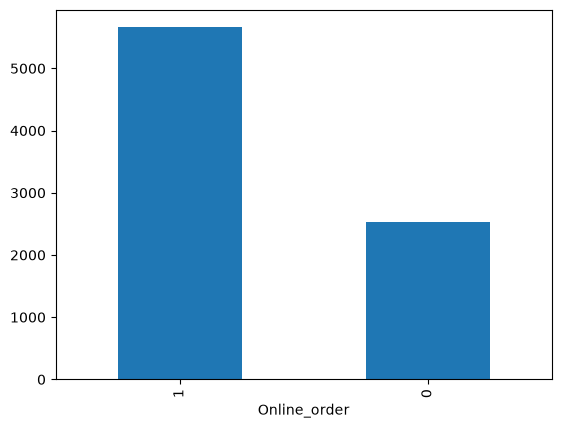

In [157]:
data['Online_order'].value_counts().plot(kind='bar')

<Axes: >

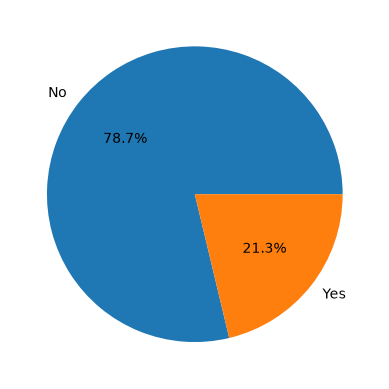

In [ ]:
data['Book_table'].value_counts().plot(kind='pie', autopct='%1.1f%%')

<Axes: xlabel='Rate'>

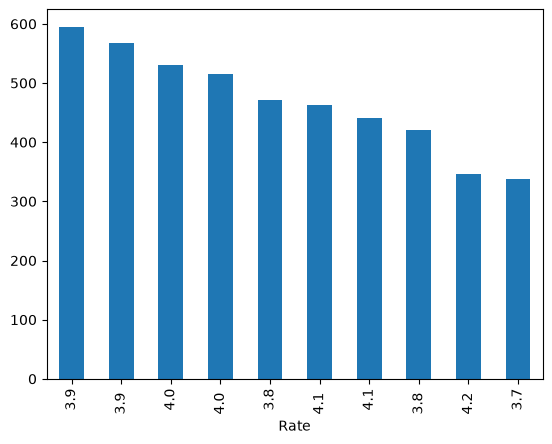

In [162]:
data['Rate'].value_counts().head(10).plot(kind='bar')

<Axes: >

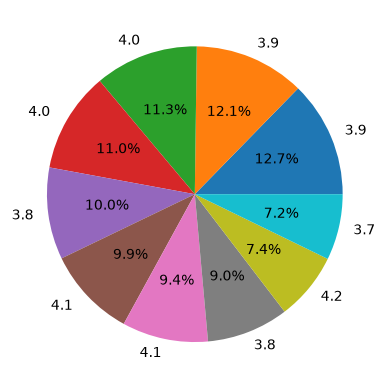

In [167]:
data['Rate'].value_counts().head(10).plot(kind='pie',autopct='%1.1f%%')

<Axes: >

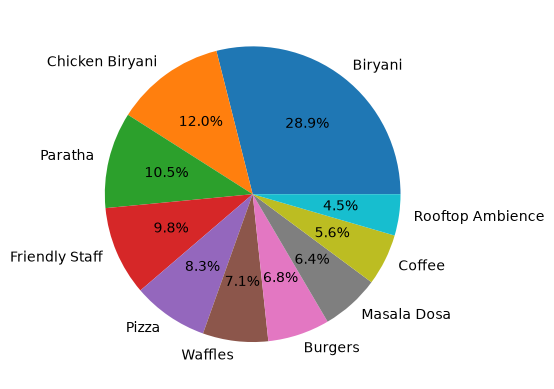

In [166]:
data['Dish_liked'].value_counts().head(10).plot(kind='pie',autopct='%1.1f%%')

<Axes: xlabel='Approx_cost(for two people)'>

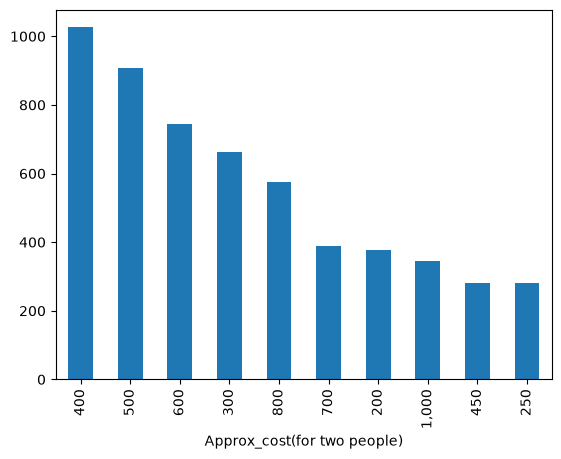

In [168]:
data['Approx_cost(for two people)'].value_counts().head(10).plot(kind='bar')

<Axes: xlabel='Online_order'>

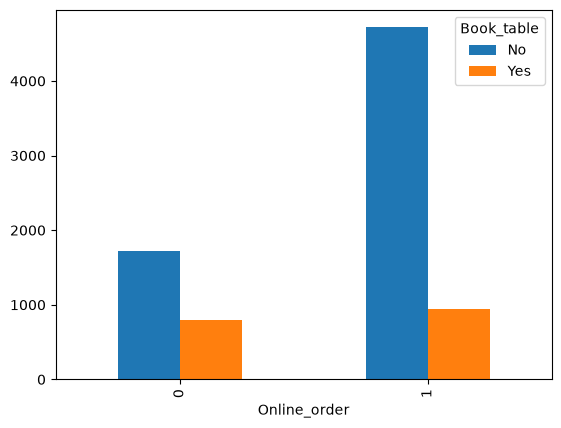

In [169]:
pd.crosstab(data['Online_order'],data['Book_table']).plot(kind='bar')

<Axes: xlabel='Book_table'>

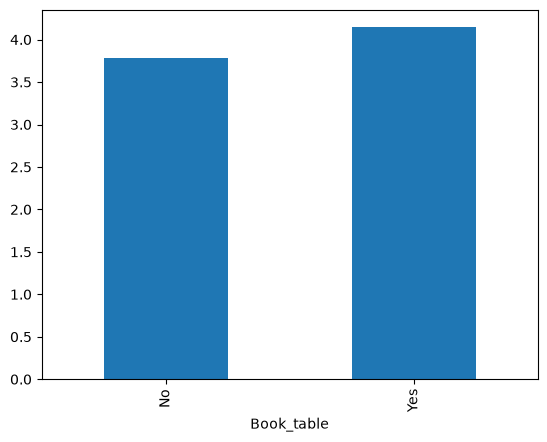

In [176]:
data['Rate'] = pd.to_numeric(data['Rate'], errors='coerce')
data.groupby('Book_table')['Rate'].mean().plot(kind='bar')

<Axes: xlabel='Approx_cost(for two people)', ylabel='Rate'>

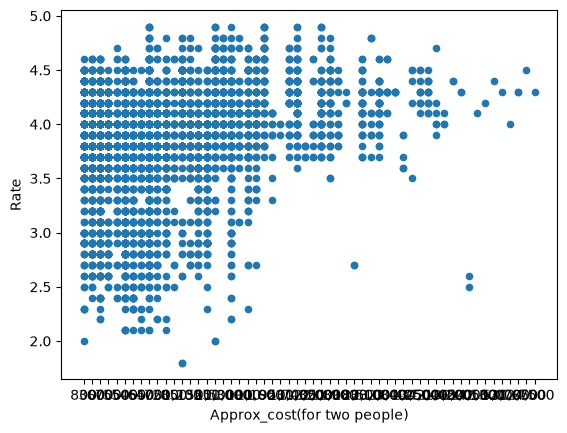

In [177]:
data.plot(x='Approx_cost(for two people)', y='Rate', kind='scatter')